# Smart picks — a small recommender for Shelf

**The question.** Shelf already suggests titles using TMDB's own "recommendations" list. Can a model that
*I train myself*, on real people's ratings, find the movies a person will like **better than just recommending
what's popular?**

**The idea in plain English.**
1. Learn a short list of numbers (a *vector*) for every movie from who liked what. Movies liked by the same kinds of people end up with similar vectors.
2. A person's taste is then simply the **sum of the vectors of the movies they liked** (called *fold-in*).
3. Recommend the movies whose vectors line up best with that taste vector.

No model has to run when someone opens the website: once the movie vectors are stored in the database, a recommendation is a single query.

**What this notebook does**

| Step | What |
|---|---|
| 1–2 | Look at the data and why recommending is hard (almost everything is unrated) |
| 3 | Split the data honestly: predict each person's *last* liked movie from what they rated *before* it |
| 4–6 | Build a popularity baseline, a genre baseline, a classic SVD model and a neural (PyTorch) model |
| 7 | Tune on a validation split, then measure **once** on a test split with confidence intervals |
| 8 | How good is it for someone who has only rated a handful of movies? (the real situation on a new Shelf) |
| 9–10 | Does it make sense? Neighbours of famous films, then recommendations for **your own** Shelf list |
| 11 | Export the vectors for the website |

*Data: MovieLens "latest-small" (GroupLens, University of Minnesota): 100,836 ratings by 610 people for 9,724 movies. Used for non-commercial learning.*

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import smartpicks as sk

EXPORT = ROOT / "export"; FIG = EXPORT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold"})
ACCENT, INK, SAGE = "#b85c52", "#3a2a2a", "#7fa58a"
import sklearn, torch
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__)

python 3.10.11 | numpy 1.26.4 | pandas 2.1.4 | scikit-learn 1.7.0 | torch 2.8.0+cpu


## 1. The data

In [2]:
d = sk.load_data()
print(f"{d.n_users} people · {d.n_items:,} movies · {len(d.ratings):,} ratings")
print(f"Only {len(d.ratings) / (d.n_users * d.n_items):.2%} of all possible (person, movie) pairs have a rating  ->  {1 - len(d.ratings) / (d.n_users * d.n_items):.1%} is empty.")
d.movies[["title", "genres", "year", "tmdbId"]].head(5)

610 people · 9,724 movies · 100,836 ratings


Only 1.70% of all possible (person, movie) pairs have a rating  ->  98.3% is empty.


,title,genres,year,tmdbId
itemIdx,,,,
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,862.0
1,Jumanji (1995),Adventure|Children|Fantasy,1995.0,8844.0
2,Grumpier Old Men (1995),Comedy|Romance,1995.0,15602.0
3,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,31357.0
4,Father of the Bride Part II (1995),Comedy,1995.0,11862.0


In [3]:
d.ratings.head(5)

,userIdx,itemIdx,rating,timestamp,pos
0,0,632,4.0,964980499,0
1,0,910,5.0,964980499,1
2,0,1492,5.0,964980523,2
3,0,1978,4.0,964980523,3
4,0,2125,4.0,964980523,4


## 2. What does the data look like?

Three things matter for recommending: how people rate, how active people are, and how **lopsided** movie popularity is.

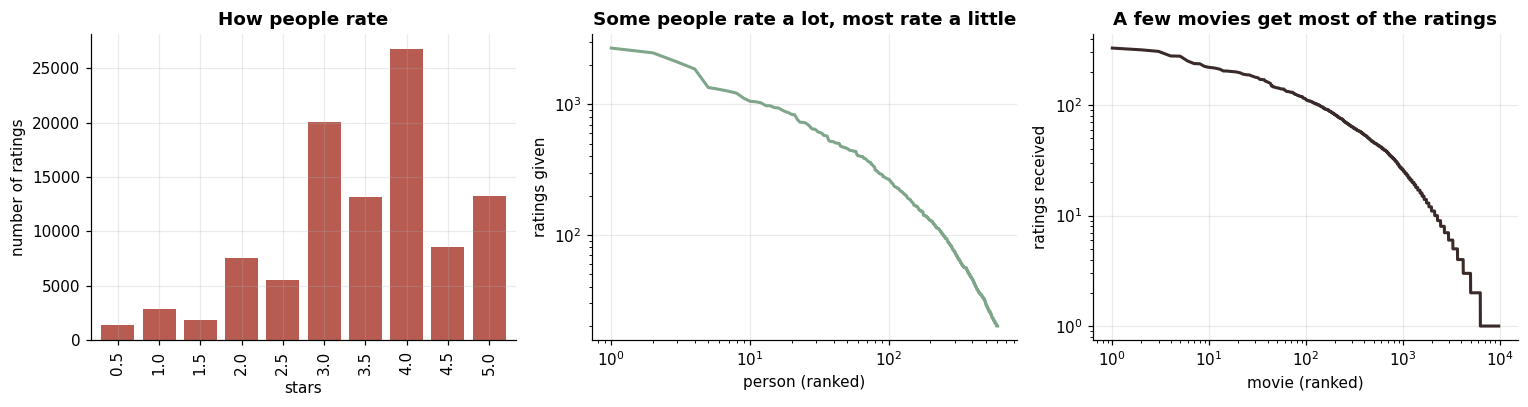

The top 10% most-rated movies receive 60% of all ratings.
62% of movies have fewer than 5 ratings, so there is very little to learn about them.


In [4]:
per_user = d.ratings.groupby("userIdx").size().sort_values(ascending=False).to_numpy()
per_item = d.ratings.groupby("itemIdx").size().sort_values(ascending=False).to_numpy()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
d.ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], color=ACCENT, width=.8)
ax[0].set(title="How people rate", xlabel="stars", ylabel="number of ratings")
ax[1].loglog(np.arange(1, len(per_user) + 1), per_user, color=SAGE, lw=2)
ax[1].set(title="Some people rate a lot, most rate a little", xlabel="person (ranked)", ylabel="ratings given")
ax[2].loglog(np.arange(1, len(per_item) + 1), per_item, color=INK, lw=2)
ax[2].set(title="A few movies get most of the ratings", xlabel="movie (ranked)", ylabel="ratings received")
plt.tight_layout(); plt.savefig(FIG / "01_data.png", bbox_inches="tight"); plt.show()

top10 = per_item[: len(per_item) // 10].sum() / per_item.sum()
print(f"The top 10% most-rated movies receive {top10:.0%} of all ratings.")
print(f"{(per_item < 5).mean():.0%} of movies have fewer than 5 ratings, so there is very little to learn about them.")

**What this tells us.** Popularity is a strong signal: the same few hits are rated by everybody. That makes
*"just recommend the popular stuff"* a hard baseline to beat, and it is exactly the baseline we must beat to claim the model
has learned anything about **individual** taste.

## 3. An honest split: predict the *next* liked movie

A model can look brilliant if it accidentally peeks at the answer. To avoid that I split **in time, per person**:

* Take each person's ratings in the order they made them.
* Hide the **last movie they liked** (4 stars or more). That is what we try to predict.
* The model may only see what that person rated **before** it.

I do this twice: a *validation* split (hide the second-to-last liked movie) to choose settings, and a *test* split (hide the last one)
that I only look at at the very end.

In [5]:
val, test = sk.make_split(d, "val"), sk.make_split(d, "test")

# no peeking: every history item must come strictly before the hidden movie, and never be the hidden movie
order = {(u, i): p for u, i, p in zip(d.ratings.userIdx, d.ratings.itemIdx, d.ratings.pos)}
for name, split in (("validation", val), ("test", test)):
    for u, target in split.targets.items():
        items, _ = split.hist[u]
        assert target not in set(items), "the answer leaked into the history"
        assert all(order[(u, int(i))] < order[(u, target)] for i in items), "history from the future"
    print(f"{name:10s}: {len(split.targets)} people to predict · {len(split.train):,} ratings available as history · leakage check passed")

validation: 603 people to predict · 96,926 ratings available as history · leakage check passed


test      : 603 people to predict · 98,633 ratings available as history · leakage check passed


### How we score it

For each person the model ranks **every movie they haven't rated yet** (about 9,700 of them) and we see where the hidden movie lands.

* **hit@10** — was the hidden movie in the top 10? (out of ~9,700 candidates, so guessing blindly would score about 0.1%)
* **NDCG@10** — like hit@10 but a rank-1 hit counts more than a rank-10 hit
* **median rank** — the typical position of the hidden movie (lower is better)
* **± value** — a 95% confidence interval, because with ~600 people a score of 8% vs 9% could easily be luck

## 4. Baselines — what we have to beat

**Popularity**: recommend the same most-liked movies to everyone.
**Genres**: build a person's taste from the genres of what they liked (no collaborative learning at all).

In [6]:
val_rows = []
def record(name, model, split=val, **kw):
    r = sk.evaluate(model, split, **kw)
    val_rows.append({"model": name, "hit@10": r["hit@10"], "±": r["ci95"], "ndcg@10": r["ndcg@10"], "median rank": r["median_rank"], "distinct movies recommended": r["distinct_recs"]})
    return r

Vg = sk.genre_vectors(d)
pop = sk.Popularity(val.train, d.n_items)
record("Popularity (same for everyone)", pop)
record("Genres only", sk.ItemVectors(Vg, "genres", "likes"))
pd.DataFrame(val_rows).round(3)

,model,hit@10,±,ndcg@10,median rank,distinct movies recommended
0,Popularity (same for everyone),0.045,0.017,0.020,487.0,114
1,Genres only,0.003,0.005,0.002,2952.5,1887


## 5. The model: PureSVD

Put everything into one big table: a row per person, a column per movie, a **1** where the person liked it, **0** everywhere else.
Then squash that table into `k` numbers per movie with a Singular Value Decomposition (SVD). Each of a movie's `k` numbers measures how
strongly it belongs to one "taste dimension" that the data revealed on its own (you can think of things like *"dark thrillers"*,
*"family animation"*, *"90s romcoms"*, but nobody labelled them).

Two knobs to tune on the **validation** split:
* `k` — how many numbers per movie (more = finer detail, but easier to overfit)
* `gamma` — how much the strongest taste dimensions dominate (0 = all equal, 1 = very dominant)

and one choice for how to build a person's taste vector from their history: from only the movies they **liked**, or from **everything** they watched.

In [7]:
grid = []
for k in (16, 32, 64, 128):
    for gamma in (0.0, 0.25, 0.5, 0.75):
        V = sk.fit_puresvd(val.train, d, k=k, gamma=gamma)
        for fold in ("likes", "ones"):
            r = sk.evaluate(sk.ItemVectors(V, "puresvd", fold), val)
            grid.append({"k": k, "gamma": gamma, "fold": fold, "hit@10": r["hit@10"], "ndcg@10": r["ndcg@10"], "median rank": r["median_rank"]})
grid = pd.DataFrame(grid).sort_values("ndcg@10", ascending=False).reset_index(drop=True)
best = grid.iloc[0]
print("Best 5 settings on the validation split (ranked by NDCG@10):")
display(grid.head(5).round(3))
print(f"\nChosen: k={int(best.k)}, gamma={best.gamma}, taste built from '{best.fold}'")

Best 5 settings on the validation split (ranked by NDCG@10):


,k,gamma,fold,hit@10,ndcg@10,median rank
0,128,0.25,likes,0.104,0.052,239.0
1,32,0.25,likes,0.103,0.051,208.0
2,16,0.00,likes,0.100,0.050,207.0
3,128,0.25,ones,0.101,0.050,220.0
4,32,0.00,likes,0.101,0.049,191.0



Chosen: k=128, gamma=0.25, taste built from 'likes'


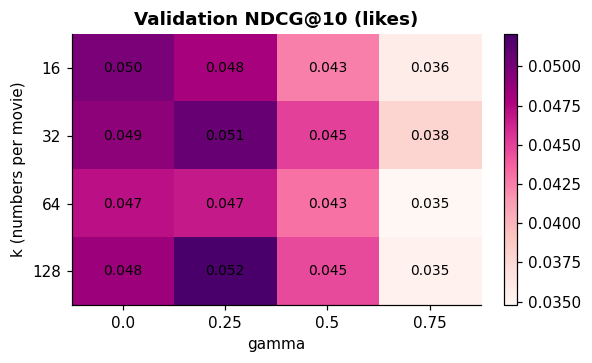

In [8]:
piv = grid[grid.fold == best.fold].pivot(index="k", columns="gamma", values="ndcg@10")
fig, ax = plt.subplots(figsize=(5.4, 3.4))
im = ax.imshow(piv.values, cmap="RdPu", aspect="auto")
ax.set_xticks(range(len(piv.columns)), piv.columns); ax.set_yticks(range(len(piv.index)), piv.index)
ax.set(xlabel="gamma", ylabel="k (numbers per movie)", title=f"Validation NDCG@10 ({best.fold})"); ax.grid(False)
for (i, j), v in np.ndenumerate(piv.values): ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.savefig(FIG / "02_tuning.png", bbox_inches="tight"); plt.show()

In [9]:
V_val = sk.fit_puresvd(val.train, d, k=int(best.k), gamma=float(best.gamma))
record("PureSVD (chosen)", sk.ItemVectors(V_val, "puresvd", best.fold))

# an older, popular variant for comparison: SVD of the *centred star ratings* instead of likes
record("Classic SVD on star ratings", sk.ItemVectors(sk.fit_svd(val.train, d, k=32), "svd", "mean"))
pd.DataFrame(val_rows).round(3)

,model,hit@10,±,ndcg@10,median rank,distinct movies recommended
0,Popularity (same for everyone),0.045,0.017,0.020,487.0,114
1,Genres only,0.003,0.005,0.002,2952.5,1887
2,PureSVD (chosen),0.104,0.024,0.052,239.0,435
3,Classic SVD on star ratings,0.065,0.020,0.032,1128.0,574


## 6. A neural alternative: BPR in PyTorch

BPR (Bayesian Personalised Ranking) learns user and movie vectors by gradient descent with one rule:
*for a person, a movie they liked should score higher than a random movie they didn't rate.*
I'll train it twice to see **overfitting** happen: once with almost no regularisation for many epochs, once more carefully.

trained two BPR models in 7s


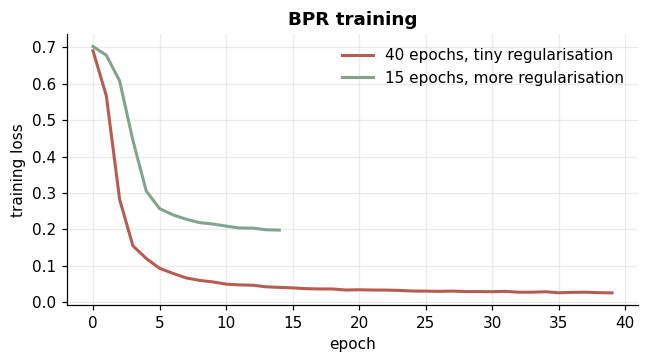

final training loss : overfit 0.025  vs  tuned 0.198
validation hit@10   : overfit 0.065  vs  tuned 0.053   (± 0.020; the two are not clearly different)
PureSVD for comparison: 0.104


,model,hit@10,±,ndcg@10,median rank,distinct movies recommended
0,Popularity (same for everyone),0.045,0.017,0.020,487.0,114
1,Genres only,0.003,0.005,0.002,2952.5,1887
2,PureSVD (chosen),0.104,0.024,0.052,239.0,435
3,Classic SVD on star ratings,0.065,0.020,0.032,1128.0,574
4,"BPR, overfit (40 ep)",0.065,0.020,0.029,283.0,409
5,"BPR, tuned (15 ep)",0.053,0.018,0.025,341.0,346


In [10]:
import time
t = time.time()
_, Q_over, loss_over = sk.fit_bpr(val.train, d, dim=32, epochs=40, lr=0.02, reg=1e-4)
_, Q_tuned, loss_tuned = sk.fit_bpr(val.train, d, dim=32, epochs=15, lr=0.01, reg=1e-2)
print(f"trained two BPR models in {time.time() - t:.0f}s")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(loss_over, color=ACCENT, lw=2, label="40 epochs, tiny regularisation")
ax.plot(loss_tuned, color=SAGE, lw=2, label="15 epochs, more regularisation")
ax.set(xlabel="epoch", ylabel="training loss", title="BPR training"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "03_bpr_loss.png", bbox_inches="tight"); plt.show()

r_over = record("BPR, overfit (40 ep)", sk.ItemVectors(Q_over, "bpr", "likes"))
r_tuned = record("BPR, tuned (15 ep)", sk.ItemVectors(Q_tuned, "bpr", "likes"))
r_svd = [r for r in val_rows if r["model"] == "PureSVD (chosen)"][0]
print(f"final training loss : overfit {loss_over[-1]:.3f}  vs  tuned {loss_tuned[-1]:.3f}")
print(f"validation hit@10   : overfit {r_over['hit@10']:.3f}  vs  tuned {r_tuned['hit@10']:.3f}   (± {r_over['ci95']:.3f}; the two are not clearly different)")
print(f"PureSVD for comparison: {r_svd['hit@10']:.3f}")
pd.DataFrame(val_rows).round(3)

**Reading this.** The overfit model reaches a much *lower training loss*, but that does not make it recommend better: low training loss only
means it fits the ratings it was shown. The validation numbers (not the loss curve) are what to trust, and they show the two BPR variants are
statistically indistinguishable, and both clearly behind the simple SVD.
On a dataset this small (100k ratings) a plain matrix factorisation beats the neural model. That is a genuine and common result:
**a more complicated model is not automatically a better one.**

## 7. Does adding genres help?

Collaborative vectors know nothing about brand-new movies with few ratings. Genres do. I try blending the two:
`[ taste vector ,  α · (typical length) · genre vector ]`, keeping the collaborative vector's length because that length carries "how widely liked this movie is".

In [11]:
rows = []
for alpha in (0.0, 0.1, 0.25, 0.5, 1.0, 2.0):
    Vh = V_val if alpha == 0 else sk.hybrid(V_val, Vg, alpha)
    r = sk.evaluate(sk.ItemVectors(Vh, "hybrid", best.fold), val)
    rows.append({"alpha (share of genres)": alpha, "hit@10": r["hit@10"], "ndcg@10": r["ndcg@10"], "median rank": r["median_rank"]})
hyb = pd.DataFrame(rows); display(hyb.round(3))
ALPHA = float(hyb.sort_values("ndcg@10", ascending=False).iloc[0]["alpha (share of genres)"])
print(f"Chosen alpha = {ALPHA}")

,alpha (share of genres),hit@10,ndcg@10,median rank
0,0.00,0.104,0.052,239.0
1,0.10,0.104,0.052,238.0
2,0.25,0.104,0.052,238.0
3,0.50,0.104,0.051,239.0
4,1.00,0.101,0.050,226.0
5,2.00,0.101,0.051,259.0


Chosen alpha = 0.0


Compare each row with alpha = 0 using the confidence interval from earlier (about ±0.02): small differences are noise. If nothing beats alpha = 0 clearly,
genres add nothing *for movies that already have many ratings*, which is expected since the collaborative signal already contains genre.
Where genres *should* matter is **new movies** that nobody has rated yet. That is a real limitation I come back to at the end.
*(My first attempt at this blend normalised away the collaborative vectors' length and crashed the score from 0.10 to 0.05; keeping the length is the fair version.)*

## 8. The test: one shot, on data the model has never seen

Settings are now frozen. I retrain on the **test** split's history and measure on the held-out last movies. I also ask whether the
improvement over popularity is bigger than luck, using a *paired bootstrap* over people.

,hit@10,±95%,ndcg@10,mrr,median rank,distinct movies
Popularity,0.041,0.016,0.023,0.024,502.0,114.0
Genres only,0.002,0.003,0.000,0.002,2836.5,1816.0
BPR (PyTorch),0.066,0.020,0.032,0.030,365.0,322.0
Smart picks (PureSVD),0.086,0.022,0.045,0.043,225.0,435.0



Smart picks hit@10 = 8.6% vs popularity 4.1%  ->  2.1x as many hits
Difference +4.5% with a 95% bootstrap interval of [+2.3%, +6.8%]  ->  clearly better than luck


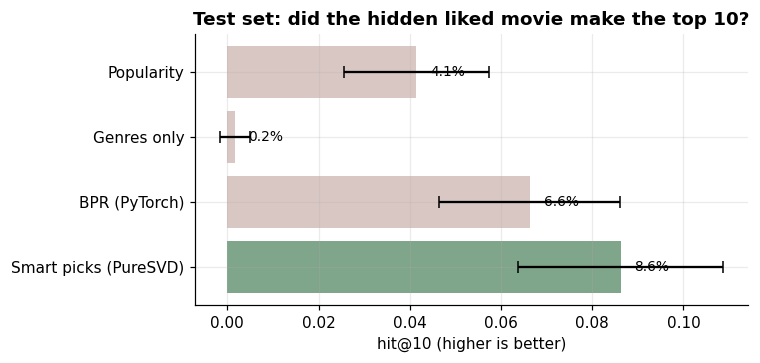

In [12]:
def final_vectors(train):
    V = sk.fit_puresvd(train, d, k=int(best.k), gamma=float(best.gamma))
    return V if ALPHA == 0 else sk.hybrid(V, Vg, ALPHA)

smart = sk.ItemVectors(final_vectors(test.train), "Smart picks", best.fold)
popT = sk.Popularity(test.train, d.n_items)
_, Q_t, _ = sk.fit_bpr(test.train, d, dim=32, epochs=15, lr=0.01, reg=1e-2)
tested = {
    "Popularity": popT,
    "Genres only": sk.ItemVectors(Vg, "genres", "likes"),
    "BPR (PyTorch)": sk.ItemVectors(Q_t, "bpr", "likes"),
    "Smart picks (PureSVD)": smart,
}
test_res = {n: sk.evaluate(m, test) for n, m in tested.items()}
tbl = pd.DataFrame({n: {"hit@10": r["hit@10"], "±95%": r["ci95"], "ndcg@10": r["ndcg@10"], "mrr": r["mrr"], "median rank": r["median_rank"], "distinct movies": r["distinct_recs"]} for n, r in test_res.items()}).T
display(tbl.round(3))

rng = np.random.default_rng(0)
a, b = test_res["Smart picks (PureSVD)"]["per_user_hit"], test_res["Popularity"]["per_user_hit"]
boot = [(a[i].mean() - b[i].mean()) for i in (rng.integers(0, len(a), len(a)) for _ in range(5000))]
lo, hi = np.percentile(boot, [2.5, 97.5])
lift = a.mean() / b.mean()
print(f"\nSmart picks hit@10 = {a.mean():.1%} vs popularity {b.mean():.1%}  ->  {lift:.1f}x as many hits")
print(f"Difference {a.mean() - b.mean():+.1%} with a 95% bootstrap interval of [{lo:+.1%}, {hi:+.1%}]  ->  " + ("clearly better than luck" if lo > 0 else "NOT distinguishable from luck"))

fig, ax = plt.subplots(figsize=(7, 3.4))
names = list(test_res); vals = [test_res[n]["hit@10"] for n in names]; errs = [test_res[n]["ci95"] for n in names]
bars = ax.barh(names, vals, xerr=errs, color=[SAGE if "Smart" in n else "#d9c7c3" for n in names], capsize=4)
ax.set(xlabel="hit@10 (higher is better)", title="Test set: did the hidden liked movie make the top 10?"); ax.invert_yaxis()
for bar, v in zip(bars, vals): ax.text(v + .003, bar.get_y() + bar.get_height() / 2, f"{v:.1%}", va="center", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "04_test_results.png", bbox_inches="tight"); plt.show()

## 9. The realistic case: someone with only a few ratings

A brand-new Shelf user might have 3 or 10 titles, not hundreds. How does the model do when it only knows each person's **first *n* ratings**?

average validation hit@10 over small histories, by hand-over point: {5: 0.03, 10: 0.033, 20: 0.032, 40: 0.034} ->  chosen n0 = 40


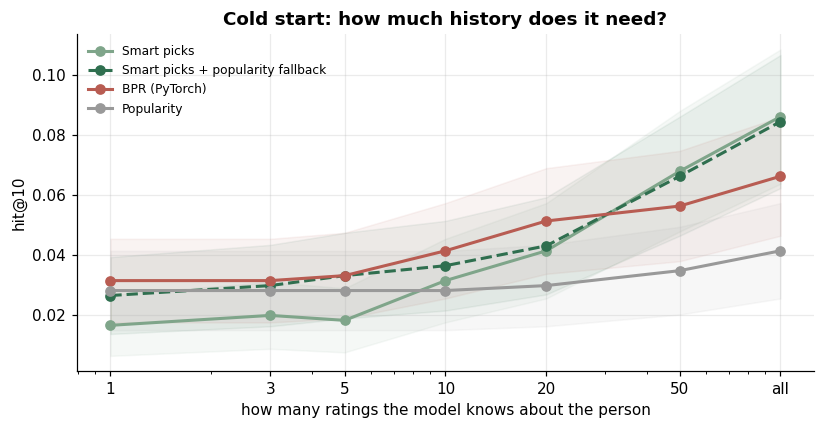

,Smart picks,Smart picks + popularity fallback,BPR (PyTorch),Popularity
ratings known,,,,
1,0.017,0.027,0.032,0.028
3,0.020,0.030,0.032,0.028
5,0.018,0.033,0.033,0.028
10,0.032,0.036,0.041,0.028
20,0.041,0.043,0.051,0.030
50,0.068,0.066,0.056,0.035
all,0.086,0.085,0.066,0.041


Smart picks (alone) first scores above popularity at 10 known ratings. NOTE the shaded bands (95% intervals, about ±0.02) overlap heavily for small histories,
so differences at 1-10 ratings are within noise; only the gap at 50+ ratings is clearly real.


In [13]:
class ColdStartBlend:
    # until a person has rated n0 titles, lean on popularity; then hand over to the personal model
    def __init__(self, model, pop, n0): self.model, self.pop, self.n0 = model, pop, n0
    def scores(self, items, ratings):
        w = min(1.0, len(items) / self.n0)
        z = lambda x: (x - x.mean()) / (x.std() + 1e-9)
        return w * z(self.model.scores(items, ratings)) + (1 - w) * z(np.log1p(self.pop.pop))

ns = [1, 3, 5, 10, 20, 50, 1000]

# choose the hand-over point n0 on the VALIDATION split (never on the test split)
val_model = sk.ItemVectors(V_val, "puresvd", best.fold)
tune = {n0: np.mean([sk.evaluate(ColdStartBlend(val_model, pop, n0), val, max_hist=n)["hit@10"] for n in (1, 3, 5, 10, 20)]) for n0 in (5, 10, 20, 40)}
N0 = max(tune, key=tune.get)
print("average validation hit@10 over small histories, by hand-over point:", {k: round(v, 3) for k, v in tune.items()}, "->  chosen n0 =", N0)

curve = {"Smart picks": [], "Smart picks + popularity fallback": [], "BPR (PyTorch)": [], "Popularity": []}
models_c = {"Smart picks": smart, "Smart picks + popularity fallback": ColdStartBlend(smart, popT, N0), "BPR (PyTorch)": tested["BPR (PyTorch)"], "Popularity": popT}
for n in ns:
    for name, m in models_c.items():
        r = sk.evaluate(m, test, max_hist=n)
        curve[name].append((r["hit@10"], r["ci95"]))

fig, ax = plt.subplots(figsize=(7.6, 4))
xs = [min(n, 100) for n in ns]
for (name, c), col, ls in zip(curve.items(), [SAGE, "#2f6f4f", ACCENT, "#999"], ["-", "--", "-", "-"]):
    y = np.array([v for v, _ in c]); e = np.array([e for _, e in c])
    ax.plot(xs, y, "o" + ls, color=col, lw=2, label=name); ax.fill_between(xs, y - e, y + e, color=col, alpha=.07)
ax.set_xscale("log"); ax.set_xticks(xs, ["1", "3", "5", "10", "20", "50", "all"])
ax.set(xlabel="how many ratings the model knows about the person", ylabel="hit@10", title="Cold start: how much history does it need?"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "05_cold_start.png", bbox_inches="tight"); plt.show()

tab = pd.DataFrame({name: [f"{v:.3f}" for v, _ in c] for name, c in curve.items()}, index=["1", "3", "5", "10", "20", "50", "all"])
tab.index.name = "ratings known"; display(tab)
first_win = next((n for n, (a_, _), (b_, _) in zip(ns, curve["Smart picks"], curve["Popularity"]) if a_ > b_), None)
print(f"Smart picks (alone) first scores above popularity at {first_win} known ratings. NOTE the shaded bands (95% intervals, about ±0.02) overlap heavily for small histories,")
print("so differences at 1-10 ratings are within noise; only the gap at 50+ ratings is clearly real.")

**What the chart honestly says.** With only a handful of ratings the personal model is **not** better than just recommending popular movies: there simply isn't enough
information about the person yet, and the shaded bands overlap. The advantage appears once a person has rated roughly **10–20+ titles** and keeps growing.

**What that means for Shelf.** Don't hand a brand-new user the raw model. The dashed line is the fix I tested: *start from popularity and hand over gradually to the personal model as history grows*
(the hand-over point was chosen on the validation split). It is a one-line rule in the website's scoring, and it avoids the worst of the cold-start dip.

## 10. Does it make sense? Look at it, don't just trust the numbers

Metrics can hide silliness. Two sanity checks: the **nearest neighbours** of films you know, and recommendations for **your own Shelf list**.

In [14]:
# train the production model on ALL ratings (the evaluation is finished, so nothing needs to be held back)
V_all = final_vectors(d.ratings)
prod = sk.ItemVectors(V_all, "Smart picks", best.fold)
Vn = normalize(V_all)
counts = d.ratings.groupby("itemIdx").size()

def find(title, year=None):
    m = d.movies[(d.movies.key == sk.norm_title(title)) & ((d.movies.year == year) if year else True)]
    return int(counts.reindex(m.index).fillna(0).idxmax()) if len(m) else None

def neighbours(title, year=None, n=7, min_ratings=20):
    i = find(title, year)
    if i is None: return f"(not in the dataset: {title})"
    sim = Vn @ Vn[i]; sim[i] = -1
    sim[counts.reindex(range(d.n_items)).fillna(0).to_numpy() < min_ratings] = -1   # a movie with 3 ratings has a meaningless vector
    top = np.argsort(-sim)[:n]
    return d.movies.loc[i, "clean_title"] + f" ({int(d.movies.loc[i, 'year'])})  →  " + ";  ".join(f"{d.movies.loc[j, 'clean_title']} ({int(d.movies.loc[j, 'year'])})" for j in top)

print("Most similar movies (only movies with 20+ ratings are considered):\n")
for t, y in [("Toy Story", 1995), ("The Matrix", 1999), ("Pulp Fiction", 1994), ("Titanic", 1997), ("Mean Girls", 2004), ("The Lion King", 1994)]:
    print(neighbours(t, y), "\n")

Most similar movies (only movies with 20+ ratings are considered):

Toy Story (1995)  →  Toy Story 2 (1999);  Down Periscope (1996);  Bio-Dome (1996);  The Nutty Professor (1996);  Space Jam (1996);  Executive Decision (1996);  Shrek (2001) 

The Matrix (1999)  →  Fight Club (1999);  Saving Private Ryan (1998);  Charlie's Angels: Full Throttle (2003);  The Terminator (1984);  Three Colors: Blue (Trois couleurs: Bleu) (1993);  Aliens (1986);  American Beauty (1999) 

Pulp Fiction (1994)  →  Get Shorty (1995);  Seven (a.k.a. Se7en) (1995);  The Silence of the Lambs (1991);  Tank Girl (1995);  The Usual Suspects (1995);  American History X (1998);  Coneheads (1993) 

Titanic (1997)  →  Air Force One (1997);  The Peacemaker (1997);  To Kill a Mockingbird (1962);  Star Wars: Episode III - Revenge of the Sith (2005);  The Notebook (2004);  Star Wars: Episode I - The Phantom Menace (1999);  Twilight (2008) 

Mean Girls (2004)  →  Never Been Kissed (1999);  Pride & Prejudice (2005);  Clueless 

### Your own list

I take the movies from `my-first-list.txt` (your original Shelf list), find them in MovieLens by title + year, pretend you liked them all (you haven't
rated them yet), and ask the model what to watch next. TV series aren't in MovieLens, and anything released after 2018 isn't either (the dataset stops in 2018),
so those can't be used.

In [15]:
lines = [l.strip() for l in (ROOT.parent / "my-first-list.txt").read_text(encoding="utf8").splitlines() if l.strip()]
import re
hist, report = [], []
for l in lines:
    m = re.match(r"^(.*?)\s*\((\d{4})\)\s*(\[series\])?$", l)
    title, year, series = m.group(1), int(m.group(2)), bool(m.group(3))
    if series: report.append((l, "series (MovieLens only has movies)")); continue
    idx = d.movies.index[(d.movies.key == sk.norm_title(title)) & (d.movies.year == year)]
    if len(idx): hist.append(int(idx[0])); continue
    # MovieLens sometimes shortens or reorders a title, so try: dataset title contained in / containing ours, same year
    tk = sk.norm_title(title)
    same_year = d.movies[d.movies.year == year]
    cand = same_year[same_year.key.str.contains(tk, regex=False)]                       # their title contains ours
    if len(cand) == 0: cand = same_year[same_year.key.map(lambda k: len(k) >= 8 and k in tk)]   # ours contains theirs (long titles only)
    if len(cand): hist.append(int(counts.reindex(cand.index).fillna(0).idxmax())); continue
    report.append((l, f"released {year}, after the dataset ends (2018)" if year > 2018 else "not found under that title"))
print(f"{len(hist)} of your {len(lines)} titles matched.   Not usable ({len(report)}):")
for l, why in report: print(f"   · {l:48s} {why}")
print("\nUsed:", "; ".join(d.movies.loc[hist, "clean_title"]))

18 of your 37 titles matched.   Not usable (19):
   · Me Before You (2016)                             not found under that title
   · Breaking Bad (2008) [series]                     series (MovieLens only has movies)
   · Young Sheldon (2017) [series]                    series (MovieLens only has movies)
   · The Good Doctor (2017) [series]                  series (MovieLens only has movies)
   · Money Heist (2017) [series]                      series (MovieLens only has movies)
   · Behind Her Eyes (2021) [series]                  series (MovieLens only has movies)
   · Bird Box (2018)                                  not found under that title
   · Lupin (2021) [series]                            series (MovieLens only has movies)
   · Geek Girl (2024) [series]                        series (MovieLens only has movies)
   · Family Switch (2023)                             released 2023, after the dataset ends (2018)
   · Gossip Girl (2007) [series]                      series (Movie

In [16]:
liked = np.full(len(hist), 4.5, dtype=np.float32)
scores = prod.scores(np.array(hist), liked)
masked = scores.copy(); masked[hist] = -np.inf
picks = np.argsort(-masked)[:12]
pct = sk.match_percent(masked.copy(), picks)
rows = []
for i, p in zip(picks, pct):
    why = sk.because(prod, hist, liked, int(i), n=2)
    rows.append({"title": f"{d.movies.loc[i, 'clean_title']} ({int(d.movies.loc[i, 'year'])})", "genres": d.movies.loc[i, "genres"].replace("|", " / "), "match": f"{p:.0f}%",
                 "because you liked": " + ".join(d.movies.loc[w, "clean_title"] for w in why)})
pd.DataFrame(rows)

,title,genres,match,because you liked
0,The Shawshank Redemption (1994),Crime / Drama,100%,Forrest Gump + Good Will Hunting
1,The Sixth Sense (1999),Drama / Horror / Mystery,82%,Forrest Gump + Titanic
2,The Lord of the Rings: The Return of the King ...,Action / Adventure / Drama / Fantasy,82%,The Lord of the Rings: The Fellowship of the R...
3,The Lord of the Rings: The Two Towers (2002),Adventure / Fantasy,78%,The Lord of the Rings: The Fellowship of the R...
4,The Silence of the Lambs (1991),Crime / Horror / Thriller,71%,Forrest Gump + Inception
5,The Dark Knight (2008),Action / Crime / Drama / IMAX,70%,Inception + The Lord of the Rings: The Fellows...
6,Fight Club (1999),Action / Crime / Drama / Thriller,69%,Inception + The Lord of the Rings: The Fellows...
7,Saving Private Ryan (1998),Action / Drama / War,64%,Forrest Gump + Inception
8,A Beautiful Mind (2001),Drama / Romance,63%,The Lord of the Rings: The Fellowship of the R...
9,The Matrix (1999),Action / Sci-Fi / Thriller,61%,Forrest Gump + Inception


**How to read "match".** It is a *relative* score between the median movie (0%) and the best-scoring movie in the whole catalogue (100%).
It is **not** a probability that you'll like it.

*Honest caveat: these are all older films, because the model only knows movies up to 2018 and your list is full of recent releases. That gap is
fixed in the website by combining this model with TMDB's candidates (see "Next steps").*

## 11. Hits vs. discovery: the popularity trap

A recommender can score well by quietly suggesting blockbusters to everyone (that is partly why popularity is a strong baseline). For Shelf that is a poor experience:
you'd rather hear about something you haven't seen. A movie's vector *length* carries how widely liked it is, so dividing each score by `length^β` pushes
suggestions toward less obvious titles. β = 0 is what we've used; larger β is more adventurous. Here is the price in accuracy.

,beta (discovery),hit@10,±,share of picks from the 100 most-rated movies,distinct movies recommended
0,0.00,0.086,0.022,0.701,435
1,0.25,0.090,0.023,0.611,560
2,0.50,0.095,0.023,0.499,748
3,0.75,0.091,0.023,0.368,1115
4,1.00,0.045,0.017,0.145,1674


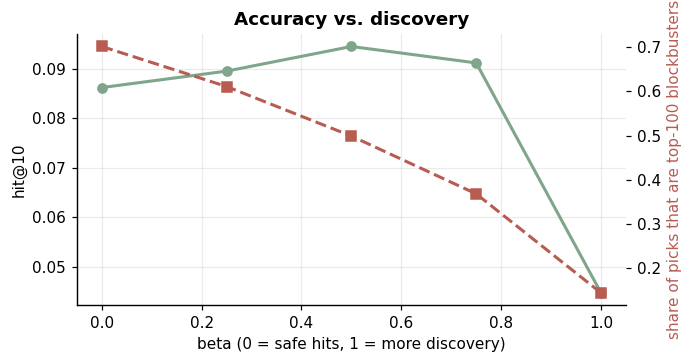

beta 0   : hit@10 0.086, 70% of picks are top-100 blockbusters, 435 distinct movies recommended
beta 0.5 : hit@10 0.095, 50% of picks are top-100 blockbusters, 748 distinct movies recommended
Moving from beta 0 to 0.5 changes hit@10 by +0.008 (the interval is about ±0.02, so that is no real loss) while recommending far less obvious movies. At beta 1 accuracy collapses.


In [17]:
class Discovery:
    def __init__(self, base, beta): self.base, self.beta = base, beta
    def scores(self, items, ratings):
        return self.base.scores(items, ratings) / (np.linalg.norm(self.base.V, axis=1) + 1e-9) ** self.beta

top100 = set(counts.sort_values(ascending=False).index[:100])
rows = []
for beta in (0.0, 0.25, 0.5, 0.75, 1.0):
    m = Discovery(smart, beta)
    r = sk.evaluate(m, test)
    shown = [x for u, tgt in test.targets.items() for x in sk.top_n(m, *test.hist[u], n=10)]
    rows.append({"beta (discovery)": beta, "hit@10": r["hit@10"], "±": r["ci95"], "share of picks from the 100 most-rated movies": np.mean([x in top100 for x in shown]), "distinct movies recommended": len(set(shown))})
disc = pd.DataFrame(rows); display(disc.round(3))
fig, ax = plt.subplots(figsize=(6.4, 3.4)); ax2 = ax.twinx()
ax.plot(disc["beta (discovery)"], disc["hit@10"], "o-", color=SAGE, lw=2, label="hit@10"); ax.set(xlabel="beta (0 = safe hits, 1 = more discovery)", ylabel="hit@10")
ax2.plot(disc["beta (discovery)"], disc["share of picks from the 100 most-rated movies"], "s--", color=ACCENT, lw=2); ax2.set_ylabel("share of picks that are top-100 blockbusters", color=ACCENT); ax2.grid(False)
ax.set_title("Accuracy vs. discovery"); plt.tight_layout(); plt.savefig(FIG / "06_discovery.png", bbox_inches="tight"); plt.show()
b0, b5 = disc.iloc[0], disc[disc["beta (discovery)"] == 0.5].iloc[0]
print(f"beta 0   : hit@10 {b0['hit@10']:.3f}, {b0['share of picks from the 100 most-rated movies']:.0%} of picks are top-100 blockbusters, {int(b0['distinct movies recommended'])} distinct movies recommended")
print(f"beta 0.5 : hit@10 {b5['hit@10']:.3f}, {b5['share of picks from the 100 most-rated movies']:.0%} of picks are top-100 blockbusters, {int(b5['distinct movies recommended'])} distinct movies recommended")
print(f"Moving from beta 0 to 0.5 changes hit@10 by {b5['hit@10'] - b0['hit@10']:+.3f} (the interval is about ±{b0['±']:.2f}, so that is no real loss) while recommending far less obvious movies. At beta 1 accuracy collapses.")

This is a **knob the website can expose** ("play it safe  ↔  surprise me"): the model stays the same, only the scoring changes, and the plot shows what each setting costs.

## 12. Export for the website

The website only needs the **movie vectors**. I save them with the TMDB id (from MovieLens' `links.csv`) so a recommended movie can be looked up on TMDB for its poster.
Scoring is a dot product: the person's taste vector is the sum of the vectors of their liked titles, and the database returns the movies with the largest dot product.

In [18]:
has_tmdb = d.movies.tmdbId.notna().to_numpy()
items = d.movies.loc[has_tmdb, ["movieId", "tmdbId", "clean_title", "year", "genres"]].copy()
items["tmdbId"] = items.tmdbId.astype(int)
items["n_ratings"] = counts.reindex(items.index).fillna(0).astype(int).to_numpy()
items.insert(0, "itemIdx", items.index)
items.rename(columns={"clean_title": "title"}).to_csv(EXPORT / "items.csv", index=False)
np.savez_compressed(EXPORT / "item_vectors.npz", tmdb_id=items.tmdbId.to_numpy(), vectors=V_all[has_tmdb].astype(np.float32))

results = {
    "dataset": "MovieLens ml-latest-small (GroupLens)", "users": d.n_users, "movies": d.n_items, "ratings": len(d.ratings),
    "model": {"type": "PureSVD on liked-movie matrix", "k": int(best.k), "gamma": float(best.gamma), "taste_from": str(best.fold), "genre_alpha": ALPHA, "vector_dim": int(V_all.shape[1])},
    "test": {n: {"hit@10": round(float(r["hit@10"]), 4), "ci95": round(float(r["ci95"]), 4), "ndcg@10": round(float(r["ndcg@10"]), 4), "median_rank": float(r["median_rank"])} for n, r in test_res.items()},
    "lift_vs_popularity": round(float(lift), 2), "lift_interval_diff": [round(float(lo), 4), round(float(hi), 4)],
}
results["discovery_tradeoff"] = disc.round(4).to_dict(orient="records")
(EXPORT / "results.json").write_text(json.dumps(results, indent=2))
print(f"exported {len(items):,} movies × {V_all.shape[1]} numbers  ->  {EXPORT}")
print((EXPORT / "item_vectors.npz").stat().st_size // 1024, "KB for the vectors")
items.rename(columns={"clean_title": "title"}).head(3)

exported 9,716 movies × 128 numbers  ->  C:\Users\Shriya\Documents\personal_library\ml\export
2606 KB for the vectors


,itemIdx,movieId,tmdbId,title,year,genres,n_ratings
itemIdx,,,,,,,
0,0,1,862,Toy Story,1995.0,Adventure|Animation|Children|Comedy|Fantasy,215
1,1,2,8844,Jumanji,1995.0,Adventure|Children|Fantasy,110
2,2,3,15602,Grumpier Old Men,1995.0,Comedy|Romance,52


In [19]:
print(f'''-- once: store the vectors (Supabase / Postgres with the pgvector extension)
create table item_vectors (tmdb_id int primary key, vec vector({V_all.shape[1]}));

-- per request: taste = sum of the vectors of the person's liked movies (computed in the app), then
select tmdb_id from item_vectors
where tmdb_id <> all(:already_seen)
order by vec <#> :taste        -- <#> is negative inner product, so smaller = better match
limit 30;''')

-- once: store the vectors (Supabase / Postgres with the pgvector extension)
create table item_vectors (tmdb_id int primary key, vec vector(128));

-- per request: taste = sum of the vectors of the person's liked movies (computed in the app), then
select tmdb_id from item_vectors
where tmdb_id <> all(:already_seen)
order by vec <#> :taste        -- <#> is negative inner product, so smaller = better match
limit 30;


## 13. Limitations and next steps

* **Movies only, and only up to 2018.** The dataset has no TV series and nothing newer. *Next:* use TMDB's candidate list for new releases and series, and rank those candidates with a content embedding of their description (so a movie nobody has rated yet can still get a vector).
* **Small data.** 610 people. A 25M-rating version (MovieLens-25M) would very likely make a neural model competitive.
* **Implicit "like" threshold.** I treat 4★+ as a like. Thumbs, rewatches or time spent would be better signals.
* **Offline metrics aren't happiness.** hit@10 on a held-out movie is a proxy. The real test is whether Shelf users add the suggestions, which the website can log.
* **Popularity bias.** Section 11 measures it and shows a knob to trade it against accuracy.
* **Fairness of the comparison.** All models see the same history and are scored on the same ~9,700 candidates; only one run per split was used, so confidence intervals (not just point values) are the honest summary.